# 4x4 Sudoku with Grover's algorithm

**Problem.** Given a partially filled $4\times4$ Sudoku ($n=2$, digits 1-4, $2\times2$ blocks), build a Grover circuit whose search space is all fillings of the blank cells, and sample a valid completed grid.

**Plan.** (1) Encoding and oracle design, (2) circuit schemes drawn with `qc.draw("mpl")`, (3) verification against an independent classical checker, (4) success curves, sampler, and resource scaling.

## 1. Design

### 1.1 Encoding

Blank cells are ordered row-major; with $k$ blanks, cell $i$ uses search qubits $(2i,2i+1)$ holding **digit $-1$** in little-endian binary. Clues are classical constants and never enter a qubit. There are $4^k$ candidate fillings.

### 1.2 Constraints

A filled grid is valid iff every row, column and block contains each digit once. For $4\times4$ this reduces to a pairwise condition: **any two cells that share a row, column or block must hold different digits**. Each unit has four cells and four available digits, so four pairwise-different cells must use each digit exactly once.

Constraints involving a clue are resolved classically before the circuit is built. Only two kinds of check remain, and each one writes its result into a **flag qubit** that is 1 when the constraint is satisfied:

| Flag | Count | Meaning | How the circuit sets it |
|---|---|---|---|
| **Domain** | one per blank | The cell's digit is not ruled out by any clue in its row, column or block. | Precompute the allowed digits (e.g. peers containing clues 2, 3, 4 leave only 1). The circuit compares the cell's two qubits against each allowed digit and flips the flag on a match. Allowed digits are mutually exclusive, so the flag is never flipped twice and a Toffoli (an XOR) is safe. |
| **Differ** | one per pair of blanks sharing a unit | The two cells hold different digits. | Compare the two cells bit by bit, flag "equal", then invert (see 1.3). |

A grid is valid exactly when **all** flags are 1. With $V$ flags, an AND ladder of Toffolis combines them using $V-1$ ancilla qubits.


### 1.3 Gates for the checks

* **Equal to a constant** $d$ (2 qubits $q_0,q_1$): apply X to each qubit where $d$ has a 0 bit, apply a Toffoli $(q_0,q_1)\to$ flag, undo the X gates. The flag toggles exactly when the cell equals $d$.
* **Two cells equal** ($a$, $b$): CX $a_0\to b_0$, CX $a_1\to b_1$ makes $b_k=a_k\oplus b_k$ (0 where equal); X on both bits makes them 1 where equal; Toffoli onto a flag gives "equal"; undo the gates to restore $b$; then X on the flag turns it into "differ".

### 1.4 Oracle in three blocks

1. **Compute checks**: all flags as above.
2. **AND and phase**: a Toffoli ladder ANDs all flags into the last ancilla, a single **Z** flips the sign if everything is valid, and the ladder is undone.
3. **Uncompute checks**: the block 1 gates in reverse order (X, CX and Toffoli are their own inverses).

### 1.5 Diffuser, iterations, sampler

The diffuser is $H^{\otimes 2k}X^{\otimes 2k}\,(\text{all-ones phase flip})\,X^{\otimes 2k}H^{\otimes 2k}$, implemented as H on the last qubit, `mcx`, H. With $N=4^k$ fillings and $M$ solutions, $P_j=\sin^2((2j+1)\theta)$ with $\theta=\arcsin\sqrt{M/N}$, and the best iteration count is $\approx\frac\pi4\sqrt{N/M}$.

The sampler does not know $M$: it follows Boyer-Brassard-Høyer-Tapp (random iteration count below a cap that grows by 6/5 on failure), validates every candidate with an independent classical checker, and returns `None` ("no solution found within budget") when the budget is spent.

In [12]:
# Make the package importable even if this kernel did not install it
# (the proper fix is `uv sync` and selecting the project's .venv kernel).
import sys
from pathlib import Path

for parent in [Path.cwd(), *Path.cwd().parents]:
    if (parent / "src" / "grover_miniproject").is_dir():
        sys.path.insert(0, str(parent / "src"))
        break

In [13]:
import time

import matplotlib.pyplot as plt

from grover_miniproject import sudoku as sd  # noqa: E402
from grover_miniproject.theory import grover_probability, optimal_iterations  # noqa: E402

plt.rcParams["figure.dpi"] = 110

SOLVED = [[1, 2, 3, 4], [3, 4, 1, 2], [2, 1, 4, 3], [4, 3, 2, 1]]


def blank(cells):
    g = [row[:] for row in SOLVED]
    for r, c in cells:
        g[r][c] = 0
    return g


def show(g):
    for row in g:
        print(" ".join(str(v) if v else "_" for v in row))


PUZZLES = {
    "one solution": blank([(0, 0), (0, 1), (1, 0)]),
    "two solutions": blank([(0, 0), (0, 1), (2, 0), (2, 1)]),
    "no solution": [[1, 2, 3, 4], [3, 4, 1, 0], [2, 1, 0, 3], [0, 3, 4, 1]],
}
for name, g in PUZZLES.items():
    print(name)
    show(g)
    print()

one solution
_ _ 3 4
_ 4 1 2
2 1 4 3
4 3 2 1

two solutions
_ _ 3 4
3 4 1 2
_ _ 4 3
4 3 2 1

no solution
1 2 3 4
3 4 1 _
2 1 _ 3
_ 3 4 1



## 2. Tracing one candidate through the checks

We run only block 1 (compute checks) on a basis state and read the flag qubits. This uses `simulate_basis`, an exact classical simulation of the X/CX/Toffoli/Z gates (they map basis states to basis states), so it is instant even for a 17-qubit circuit.

In [14]:
g = PUZZLES["one solution"]
cells = sd.empties(g)
pair_list = sd.pairs(g)
search, flags, anc = sd.layout(g)
names = [f"domain{c}" for c in cells] + [
    f"differ{cells[i]}-{cells[j]}" for i, j in pair_list
]
print("allowed digits per blank:", {c: sd.allowed_digits(g, c) for c in cells})
print("flag order:", names)

compute = sd.compute_checks_circuit(g)
for digits in [(2, 1, 3), (1, 2, 3)]:
    zval = sum((d - 1) << (2 * i) for i, d in enumerate(digits))
    out, _ = sd.simulate_basis(compute, zval)
    flag_bits = [(out >> q) & 1 for q in flags]
    sign = sd.oracle_signs(g)[zval]
    print(
        f"candidate {digits}: flags = {flag_bits}  all ones = {all(flag_bits)}  oracle sign = {sign:+d}"
    )

allowed digits per blank: {(0, 0): [1], (0, 1): [2], (1, 0): [3]}
flag order: ['domain(0, 0)', 'domain(0, 1)', 'domain(1, 0)', 'differ(0, 0)-(0, 1)', 'differ(0, 0)-(1, 0)', 'differ(0, 1)-(1, 0)']
candidate (2, 1, 3): flags = [0, 0, 1, 1, 1, 1]  all ones = False  oracle sign = +1
candidate (1, 2, 3): flags = [1, 1, 1, 1, 1, 1]  all ones = True  oracle sign = -1


The valid candidate $(1,2,3)$ has every flag equal to 1, so the AND is 1 and the Z flips its sign. The invalid candidate fails at least one flag, so the AND is 0 and nothing happens.

## 3. Circuit schemes

**3.1 One blank cell, gate level.** 2 search qubits, 1 domain flag, no ancillas. Read left to right: the X gates and Toffoli test the cell against each allowed digit (here only one), then the Z, then the uncompute.

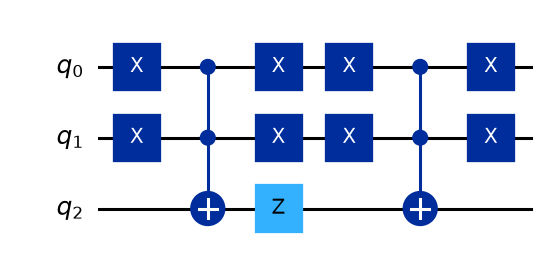

In [15]:
one_blank = blank([(0, 0)])
sd.sudoku_oracle(one_blank).draw("mpl", fold=45)

**3.2 Two blanks in the same row, gate level.** 4 search qubits, 2 domain flags, 1 differ flag, 2 ancillas. The CX-X-Toffoli-X-CX pattern in the middle is the "two cells equal" check; the Toffoli ladder before the Z ANDs the three flags.

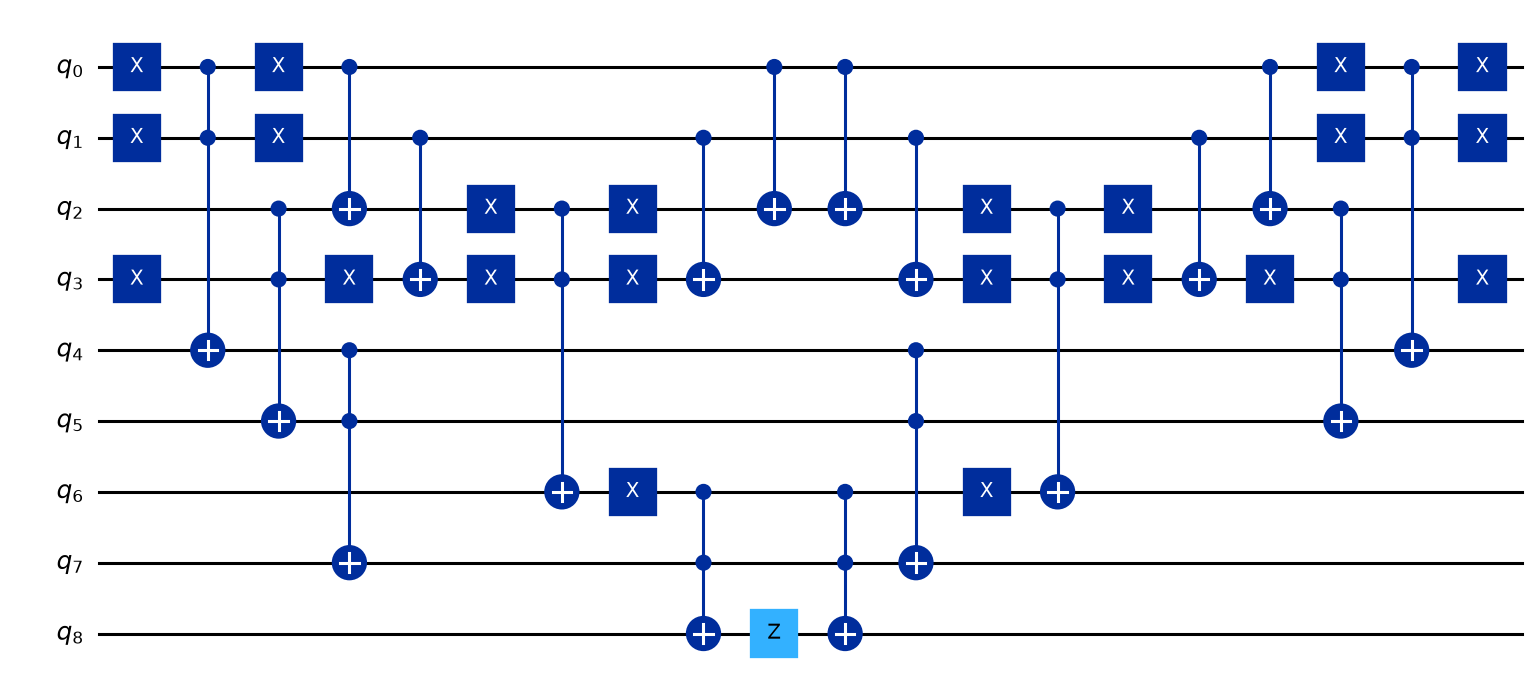

In [16]:
two_blanks = blank([(0, 0), (0, 1)])
sd.sudoku_oracle(two_blanks).draw("mpl", fold=45)

**3.3 One Grover iteration of the one-solution puzzle as blocks.** (17 qubits, so the gate-level circuit is too wide to read.)

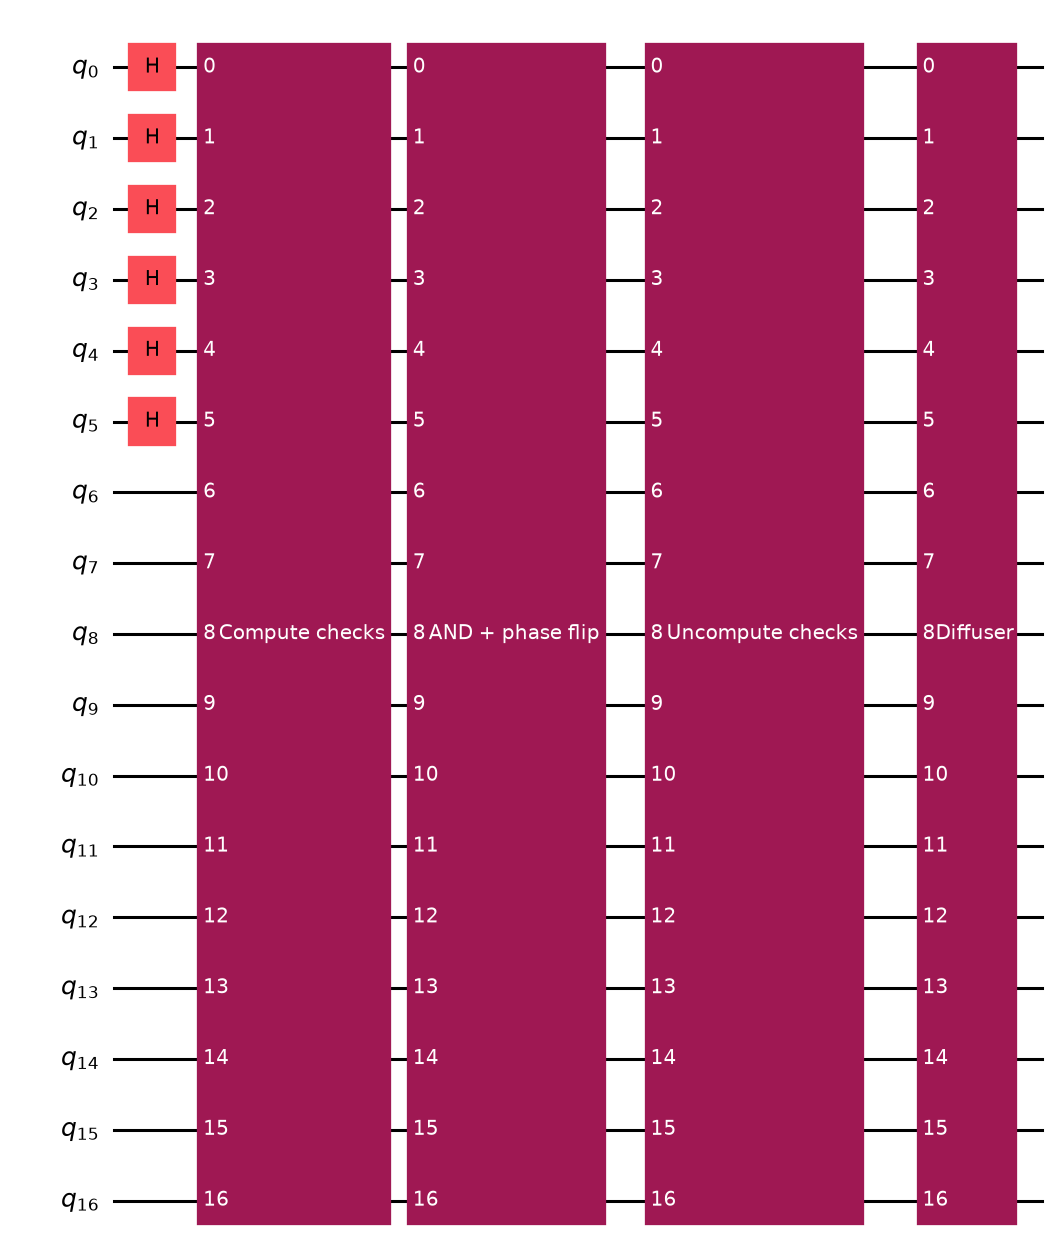

In [17]:
sd.grover_block_circuit(PUZZLES["one solution"]).draw("mpl", fold=-1)

## 4. Oracle verification

For every puzzle and every one of the $4^k$ assignments, the oracle's sign must equal $-1$ exactly when an **independent classical checker** (`is_valid_grid`, which does not share code with the circuit) accepts the filled grid, and every flag and ancilla qubit must return to $|0\rangle$. Because the oracle is a permutation of basis states plus a sign, correct basis-state action implies correct action on superpositions by linearity. Everything is exact, so no numerical tolerance is needed.

As an extra cross-check on the smallest puzzle we also run Qiskit's own `Statevector` (tolerance `1e-12`; the gates have no irrational angles, so rounding is about `1e-16`).

In [18]:
print(f"{'puzzle':<16}{'blanks':<8}{'candidates':<12}{'solutions':<11}{'oracle OK'}")
for name, g in PUZZLES.items():
    sd.check_oracle(g)
    k = len(sd.empties(g))
    print(f"{name:<16}{k:<8}{4**k:<12}{len(sd.brute_force_solutions(g)):<11}True")

sd.check_oracle_statevector(PUZZLES["one solution"])
print("Qiskit Statevector cross-check on 'one solution': OK")

puzzle          blanks  candidates  solutions  oracle OK
one solution    3       64          1          True
two solutions   4       256         2          True
no solution     3       64          0          True
Qiskit Statevector cross-check on 'one solution': OK


## 5. Success probability against iteration count

Dots: simulation of the search register using the oracle's verified signs. Lines: closed form $\sin^2((2k+1)\theta)$. Reducing the simulation to the search register is valid because the oracle is diagonal there once all work qubits are clean (checked above); the diffuser equals $2|s\rangle\langle s|-I$ up to a global phase.

one solution     max |sim - theory| = 1.7e-16   k_opt = 6   sim time 0.013s
two solutions    max |sim - theory| = 1.1e-16   k_opt = 8   sim time 0.081s
no solution      max |sim - theory| = 0.0e+00   k_opt = 0   sim time 0.002s


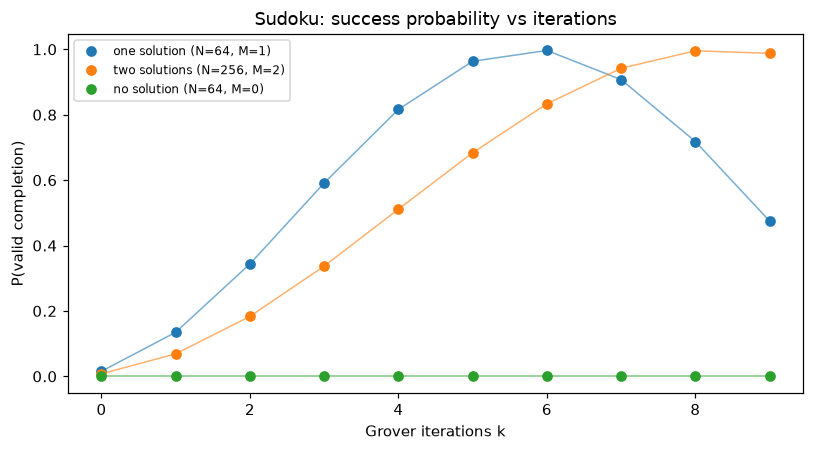

In [19]:
max_iter = 9
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for name, g in PUZZLES.items():
    k = len(sd.empties(g))
    m_i = len(sd.brute_force_solutions(g))
    n_total = 4**k
    t0 = time.perf_counter()
    sim = sd.success_curve(g, max_iter)
    sim_time = time.perf_counter() - t0
    theory = [grover_probability(n_total, m_i, j) for j in range(max_iter + 1)]
    err = max(abs(a - b) for a, b in zip(sim, theory, strict=True))
    (line,) = ax.plot(range(max_iter + 1), theory, lw=1, alpha=0.6)
    ax.plot(
        range(max_iter + 1),
        sim,
        "o",
        color=line.get_color(),
        label=f"{name} (N={n_total}, M={m_i})",
    )
    print(
        f"{name:<16} max |sim - theory| = {err:.1e}   k_opt = {optimal_iterations(n_total, m_i)}   sim time {sim_time:.3f}s"
    )
ax.set_xlabel("Grover iterations k")
ax.set_ylabel("P(valid completion)")
ax.set_title("Sudoku: success probability vs iterations")
ax.legend(fontsize=8)
fig.tight_layout()

The one-solution puzzle ($N=64$) peaks near iteration 6 and then falls (overshoot). The two-solution puzzle has $N=256$, so it needs more iterations in absolute terms ($\approx 8$), but is faster than a single solution would be. With no solution nothing is ever marked.

## 6. Sampler

`sample_solution` returns a validated completed grid or `None`.

In [20]:
for name, g in PUZZLES.items():
    out = sd.sample_solution(g, max_trials=40, seed=1)
    print(name)
    if out is None:
        print("  -> no solution found within budget")
    else:
        show(out)
        print("  valid:", sd.is_valid_grid(out))

one solution
1 2 3 4
3 4 1 2
2 1 4 3
4 3 2 1
  valid: True
two solutions
2 1 3 4
3 4 1 2
1 2 4 3
4 3 2 1
  valid: True
no solution
  -> no solution found within budget


## 7. Resources against the number of blank cells

All counts are for **one oracle call**, in the gates the oracle actually uses ($X$, CX, Toffoli, $Z$), with all-to-all connectivity assumed. The `iters` column is the optimal number of Grover iterations (= total oracle calls) for that puzzle's true number of solutions $M$, $\approx\frac\pi4\sqrt{4^k/M}$; it is shown for scale only and is not used by the solver.

Blanks are taken from the grid in the order (0,0), (0,1), (1,0), (1,1), (0,2). Fewer clues mean more domain flags *and* more differ flags (every pair of blanks in a shared unit adds one), so the qubit count and gate count grow faster than linearly in $k$.

 k  search  work  qubits    X   CX  CCX   Z  gates  depth   iters
 1       2     1       3    8    0    2   1     11      6       1
 2       4     5       9   22    8   10   1     41     17       3
 3       6    11      17   46   24   22   1     93     37       6
 4       8    19      27   76   48   38   1    163     57      12
 5      10    25      35  104   64   52   1    221     73      25


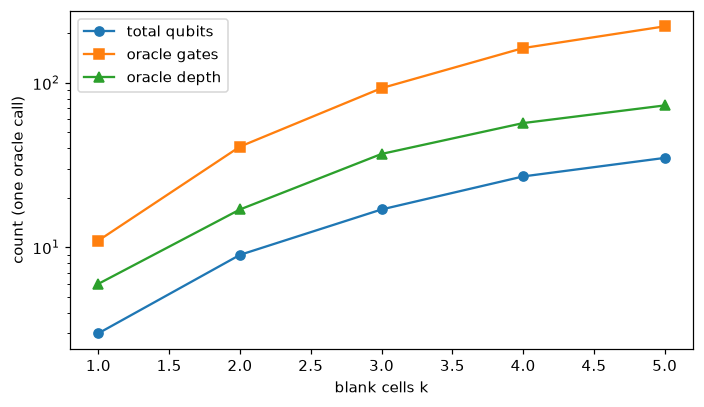

In [21]:
order = [(0, 0), (0, 1), (1, 0), (1, 1), (0, 2)]
rows = []
print(
    f"{'k':>2}{'search':>8}{'work':>6}{'qubits':>8}{'X':>5}{'CX':>5}{'CCX':>5}{'Z':>4}{'gates':>7}{'depth':>7}{'iters':>8}"
)
for k in range(1, 6):
    g = blank(order[:k])
    r = sd.resources(g)
    ops = r["oracle_gates"]
    total = sum(ops.values())
    calls = optimal_iterations(4**k, max(1, len(sd.brute_force_solutions(g))))
    rows.append((k, r["search_qubits"] + r["work_qubits"], total, r["oracle_depth"]))
    print(
        f"{k:>2}{r['search_qubits']:>8}{r['work_qubits']:>6}{r['search_qubits'] + r['work_qubits']:>8}"
        f"{ops.get('x', 0):>5}{ops.get('cx', 0):>5}{ops.get('ccx', 0):>5}{ops.get('z', 0):>4}{total:>7}{r['oracle_depth']:>7}{calls:>8}"
    )

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ks = [r[0] for r in rows]
ax.plot(ks, [r[1] for r in rows], "o-", label="total qubits")
ax.plot(ks, [r[2] for r in rows], "s-", label="oracle gates")
ax.plot(ks, [r[3] for r in rows], "^-", label="oracle depth")
ax.set_xlabel("blank cells k")
ax.set_ylabel("count (one oracle call)")
ax.set_yscale("log")
ax.legend()
fig.tight_layout()

In [22]:
# Circuit cost vs classical simulation cost: the simulation grows with 4^k even
# though the circuit grows polynomially in this table.
for k in range(1, 6):
    g = blank(order[:k])
    t0 = time.perf_counter()
    sd.success_curve(g, 3)
    print(
        f"k={k}: classical simulation of the search register ({4**k} amplitudes) took {time.perf_counter() - t0:.3f}s"
    )

k=1: classical simulation of the search register (4 amplitudes) took 0.001s
k=2: classical simulation of the search register (16 amplitudes) took 0.002s
k=3: classical simulation of the search register (64 amplitudes) took 0.013s
k=4: classical simulation of the search register (256 amplitudes) took 0.084s
k=5: classical simulation of the search register (1024 amplitudes) took 0.461s


**Circuit cost vs simulation time.** The table above describes the *quantum circuit*. The seconds printed afterward are the time of a classical simulation, which scales with $4^k$ no matter how small the circuit is; they say nothing about quantum hardware. A full statevector of the 17-qubit one-solution circuit has $2^{17}$ amplitudes, and a 23-qubit one has $2^{23}$, which is why the search-register simulation is used for the curves.

## 8. Conclusions and limitations

* The oracle matches the independent classical checker for all assignments of puzzles with one, two and no solutions, and returns all work qubits to $|0\rangle$.
* Success curves follow the closed form; the sampler returns only validated grids and reports "no solution found within budget" otherwise.
* Limitations: only $4\times4$ grids; the number of work qubits grows quickly with the number of blank cells (use puzzles with few blanks); full-circuit statevector simulation is limited to about 20 qubits; connectivity is assumed all-to-all.
* Extension: for $9\times9$ use 4-qubit digits plus a range check (digits 10-15 invalid), and reduce work qubits by reusing ancillas between checks.